## 📓 Notebook 05: SVM, KNN & Naive Bayes

**Skills practiced:** Scaled vs. unscaled model comparison, kernel choice, tuning `k`, timing `.fit()` calls.

**Goal:** Measure exactly how much feature scaling changes SVM/KNN performance, and benchmark Naive Bayes's speed against the other models.

In [3]:
import time

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import recall_score, accuracy_score, classification_report, r2_score, roc_auc_score

from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB


x_train_uns=pd.read_csv('../data/processed/X_train.csv')
x_test_uns=pd.read_csv('../data/processed/X_test.csv')
x_train=pd.read_csv('../data/processed/x_train_scaled.csv')
x_test=pd.read_csv('../data/processed/x_test_scaled.csv')
y_train=pd.read_csv("../data/processed/Y_train.csv").squeeze()
y_test=pd.read_csv("../data/processed/Y_test.csv").squeeze()

In [2]:
SVM=SVC(kernel='linear', max_iter=500000)
SVM.fit(x_train_uns, y_train)
SVM_pred=SVM.predict(x_test_uns)

print(round(accuracy_score(y_test, SVM_pred),3))

print(round(recall_score(y_test, SVM_pred), 3))

scores = SVM.decision_function(x_test_uns)
ras = roc_auc_score(y_test, scores)
print(round(ras, 4))

c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\svm\_base.py:340: ConvergenceWarning: Solver terminated early (max_iter=500000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


0.863
0.669
0.7919


In [3]:
SVM2=SVC(kernel='linear', max_iter=500000)
SVM2.fit(x_train, y_train)
SVM2_pred=SVM2.predict(x_test)
print(round(accuracy_score(y_test, SVM2_pred),3))

scores2 = SVM2.decision_function(x_test)

print(round(recall_score(y_test, SVM2_pred), 3))

ras2 = roc_auc_score(y_test, scores2)
print(round(ras2, 4))

c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\svm\_base.py:340: ConvergenceWarning: Solver terminated early (max_iter=500000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


0.931
0.66
0.8365


In [ ]:
print("AUC unscaled:", round(ras, 4))
print("AUC scaled:  ", round(ras2, 4))
diff = ras2-ras
print("difference:  ", round(diff, 4), "=", round(diff * 100, 2), "AUC points")

AUC unscaled: 0.7919
AUC scaled:   0.8365
difference:   -0.0445 = -4.45 AUC points


In [ ]:
SVM3=SVC(kernel='rbf', class_weight="balanced", cache_size=2000)
SVM3.fit(x_train, y_train)
SVM3_pred=SVM3.predict(x_test)

print(round(accuracy_score(y_test, SVM3_pred),3))

print(round(recall_score(y_test, SVM3_pred), 3))

scores3 = SVM3.decision_function(x_test)
ras3 = roc_auc_score(y_test, scores3)
print("ROC-AUC:", round(ras3, 4))

0.906
0.536
ROC-AUC: 0.852


In [6]:
print("AUC 'linear' kernel:", round(ras2, 4))
print("AUC 'rbf' kernel:  ", round(ras3, 4))
diff = ras2-ras3
print("difference:  ", round(diff, 4), "=", round(diff * 100, 2), "AUC points")

AUC 'linear' kernel: 0.8365
AUC 'rbf' kernel:   0.852
difference:   -0.0156 = -1.56 AUC points


In [5]:
results={}
for k in [3,10,25,50,100]:
    KNC=KNeighborsClassifier(n_neighbors=k)
    KNC.fit(x_train, y_train)
    probs = KNC.predict_proba(x_test)[:, 1]
    results[k] = roc_auc_score(y_test, probs)
    print("k =", k, "ROC-AUC =", round(results[k], 4))

k = 3 ROC-AUC = 0.7138
k = 10 ROC-AUC = 0.7431
k = 25 ROC-AUC = 0.7585
k = 50 ROC-AUC = 0.7646
k = 100 ROC-AUC = 0.7661


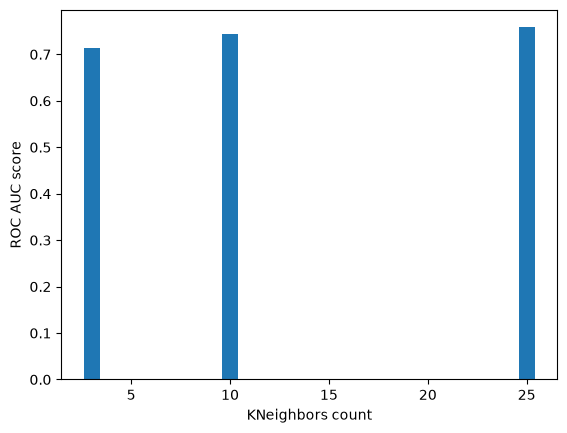

In [8]:
plt.bar(list(results.keys()), list(results.values()))
plt.xlabel("KNeighbors count")
plt.ylabel("ROC AUC score")
plt.show()

In [9]:
start_time = time.time()

GNB = GaussianNB()
GNB.fit(x_train, y_train)

probs = GNB.predict_proba(x_test)[:, 1]

auc = roc_auc_score(y_test, probs)

end_time = time.time()

elapsed_seconds = end_time - start_time

print("Naive Bayes ROC-AUC:", round(auc, 4))
print(f"Naive Bayes execution time: {elapsed_seconds:.2f} seconds")
print(f"Naive Bayes execution time: {elapsed_seconds / 60:.2f} minutes")

Naive Bayes ROC-AUC: 0.8386
Naive Bayes execution time: 1.11 seconds
Naive Bayes execution time: 0.02 minutes
